In [1]:
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import datetime as dt

# Run from analysis/: mongo_common reads MONGO_URI / MONGO_DB from the repo's .env.
sys.path.insert(0, "../scripts")
from mongo_common import get_db

print('libraries loaded')

libraries loaded


In [2]:
db = get_db()

**Insight 1: Median and IQR by fiscal week**

In [3]:
df = pd.DataFrame(db.contracts_past_transactions.find(
    {}, {"_id": 0, "action_date": 1, "federal_action_obligation": 1}))

In [4]:
df

,federal_action_obligation,action_date
0,0.00,2020-05-21
1,90000.00,2020-05-22
2,45000.00,2020-06-30
3,248751.00,2020-09-16
4,0.00,2020-09-24
...,...,...
6341,-62983.76,2025-09-04
6342,0.00,2025-01-10
6343,0.00,2025-06-11
6344,8350.00,2025-03-11


In [5]:
df['action_date'] = pd.to_datetime(df['action_date'])

In [6]:
df['fy'] = df['action_date'].dt.year + (df['action_date'].dt.month >= 10).astype(int)


In [7]:
df['fy_start'] = pd.to_datetime(df['fy'].astype(str) + '-10-01') - pd.DateOffset(years=1)

In [8]:
df['fiscal_week'] = (df['action_date'] - df['fy_start']).dt.days // 7

In [9]:
weekly = df.groupby(['fy', 'fiscal_week'])['federal_action_obligation'].sum().reset_index()

In [10]:
stats = weekly.groupby('fiscal_week')['federal_action_obligation'].agg(
    median='median',
    q25=lambda s: s.quantile(0.25),
    q75=lambda s: s.quantile(0.75),
    n='size'
).reset_index()

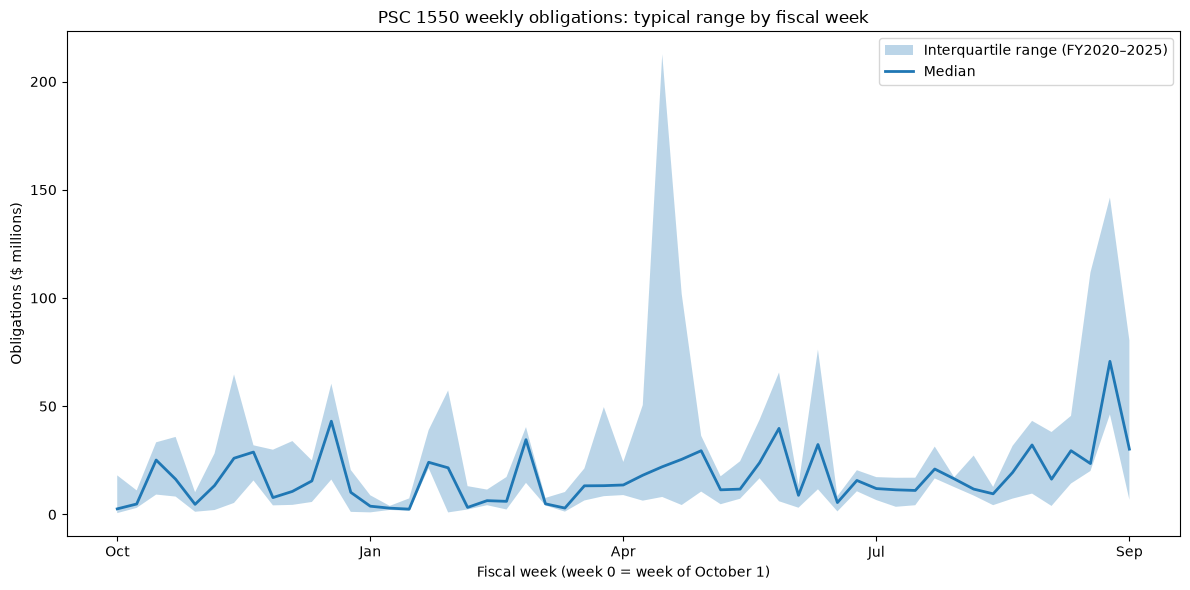

In [11]:
stats['median_m'] = stats['median'] / 1_000_000
stats['q25_m'] = stats['q25'] / 1_000_000
stats['q75_m'] = stats['q75'] / 1_000_000

fig, ax = plt.subplots(figsize=(12, 6))

ax.fill_between(stats['fiscal_week'], stats['q25_m'], stats['q75_m'],
                alpha=0.3, label='Interquartile range (FY2020–2025)')

ax.plot(stats['fiscal_week'], stats['median_m'],
        linewidth=2, label='Median')

ax.set_xlabel('Fiscal week (week 0 = week of October 1)')
ax.set_ylabel('Obligations ($ millions)')
ax.set_title('PSC 1550 weekly obligations: typical range by fiscal week')
ax.set_xticks([0, 13, 26, 39, 52])
ax.set_xticklabels(['Oct', 'Jan', 'Apr', 'Jul', 'Sep'])
ax.legend()

plt.tight_layout()
plt.show()

**Insight 2: Median and IQR by fiscal month**

In [12]:
df['fiscal_month'] = (df['action_date'].dt.month - 10) % 12 + 1

In [13]:
monthly = df.groupby(['fy', 'fiscal_month'])['federal_action_obligation'].sum().reset_index()

In [14]:
stats_m = monthly.groupby('fiscal_month')['federal_action_obligation'].agg(
    median='median',
    q25=lambda s: s.quantile(0.25),
    q75=lambda s: s.quantile(0.75)
).reset_index()

for col in ['median', 'q25', 'q75']:
    stats_m[col] = stats_m[col] / 1_000_000

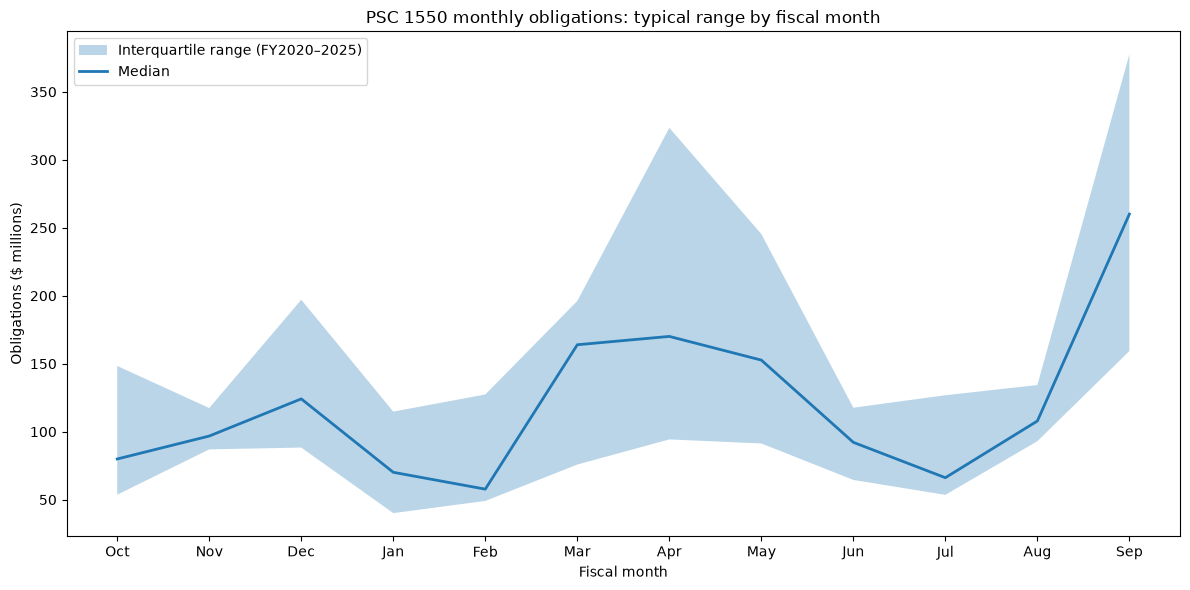

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.fill_between(stats_m['fiscal_month'], stats_m['q25'], stats_m['q75'],
                alpha=0.3, label='Interquartile range (FY2020–2025)')

ax.plot(stats_m['fiscal_month'], stats_m['median'],
        linewidth=2, label='Median')

ax.set_xlabel('Fiscal month')
ax.set_ylabel('Obligations ($ millions)')
ax.set_title('PSC 1550 monthly obligations: typical range by fiscal month')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep'])
ax.legend()

plt.tight_layout()
plt.show()

**Insight 2: Weekly rankings**

In [16]:
df.head

<bound method NDFrame.head of       federal_action_obligation action_date    fy   fy_start  fiscal_week  \
0                          0.00  2020-05-21  2020 2019-10-01           33   
1                      90000.00  2020-05-22  2020 2019-10-01           33   
2                      45000.00  2020-06-30  2020 2019-10-01           39   
3                     248751.00  2020-09-16  2020 2019-10-01           50   
4                          0.00  2020-09-24  2020 2019-10-01           51   
...                         ...         ...   ...        ...          ...   
6341                  -62983.76  2025-09-04  2025 2024-10-01           48   
6342                       0.00  2025-01-10  2025 2024-10-01           14   
6343                       0.00  2025-06-11  2025 2024-10-01           36   
6344                    8350.00  2025-03-11  2025 2024-10-01           23   
6345                       0.00  2024-12-05  2025 2024-10-01            9   

      fiscal_month  
0                8  
1  

In [17]:
def weekly_rank(weekly_amount, fiscal_week, weekly_history):
    reference = weekly_history[(weekly_history['fiscal_week'] >= fiscal_week - 2) & (weekly_history['fiscal_week'] <= fiscal_week + 2)]['federal_action_obligation']
    # I'm choosing within the range of 5 weeks because it reflects both seasonality and gives a sample size of 5 similar weeks across 6 years.
    percentile = (reference < weekly_amount).sum() / len(reference) * 100
    rank = (reference >= weekly_amount).sum() + 1
    reference_median = reference.median()
    reference_count = len(reference)
    return percentile, rank, reference_median, reference_count

In [18]:
weekly_rank(weekly_amount=100000000, fiscal_week=40, weekly_history= weekly)

(np.float64(96.66666666666667), np.int64(2), np.float64(16347036.99), 30)

In [19]:
from datetime import timedelta, date

In [20]:
today_last_week = dt.date.today() - timedelta(days=7)

In [21]:
# usaspending_loader fills this collection with a 14-day window (D12); rank only the latest 7 days.
week = db.contracts_weekly_transactions_all.aggregate([
    {"$match": {"action_date": {"$gte": dt.datetime.combine(today_last_week, dt.time()),
                                "$lte": dt.datetime.combine(dt.date.today(), dt.time())}}},
    {"$group": {"_id": None, "total": {"$sum": "$transaction_amount"}}},
])
weekly_amount = next(week, {"total": 0})["total"]
print(weekly_amount)

0


In [22]:
fiscal_year = (today_last_week.year) + (today_last_week.month >= 10)
fiscal_year_start = dt.date(fiscal_year - 1, 10, 1)
fiscal_week = (today_last_week - fiscal_year_start).days // 7

In [23]:
weekly_rank(weekly_amount=weekly_amount, fiscal_week=fiscal_week, weekly_history=weekly)

(np.float64(16.666666666666664),
 np.int64(16),
 np.float64(5421674.600000001),
 18)

**Insight 3: Competition Metrics**

In [24]:
competed_categories = [
    'FULL AND OPEN COMPETITION',
    'COMPETED UNDER SAP',
    'FULL AND OPEN COMPETITION AFTER EXCLUSION OF SOURCES',
]

comp = pd.DataFrame(db.contracts_past_transactions.find({}, {
    "_id": 0, "extent_competed": 1, "type_of_set_aside": 1,
    "fy": "$action_date_fiscal_year", "amt": "$federal_action_obligation",
}))

comp = comp[comp['extent_competed'].notna()]
comp['competed'] = comp['extent_competed'].isin(competed_categories)
comp['competed_amt'] = comp['amt'].where(comp['competed'], 0)

trend = comp.groupby('fy').agg(
    n=('competed', 'size'),
    pct_competed=('competed', 'mean'),
    total_amt=('amt', 'sum'),
    competed_amt=('competed_amt', 'sum'),
).reset_index()

trend['pct_competed'] = (trend['pct_competed'] * 100).round(1)
trend['pct_dollars_competed'] = (trend['competed_amt'] / trend['total_amt'] * 100).round(1)

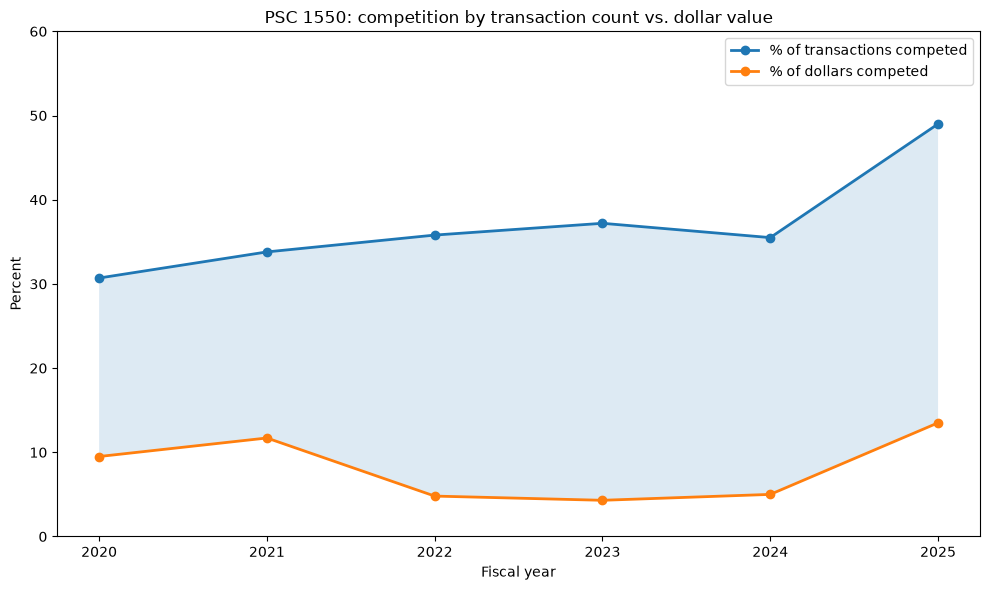

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(trend['fy'], trend['pct_competed'],
        marker='o', linewidth=2, label='% of transactions competed')

ax.plot(trend['fy'], trend['pct_dollars_competed'],
        marker='o', linewidth=2, label='% of dollars competed')

ax.fill_between(trend['fy'], trend['pct_dollars_competed'], trend['pct_competed'],
                alpha=0.15)

ax.set_ylabel('Percent')
ax.set_xlabel('Fiscal year')
ax.set_title('PSC 1550: competition by transaction count vs. dollar value')
ax.set_xticks(trend['fy'])
ax.set_ylim(0, 60)
ax.legend()

plt.tight_layout()
plt.show()